In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

%matplotlib inline

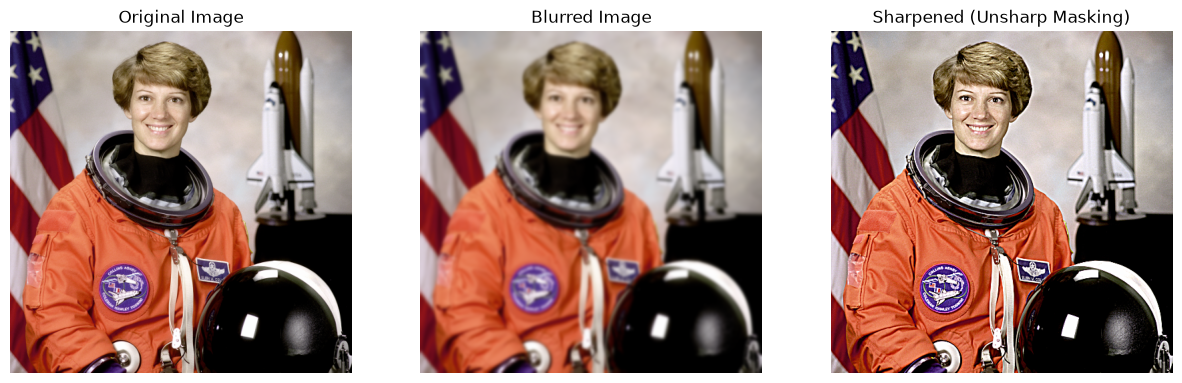

In [2]:
image = data.astronaut()

# Gaussian sigma (blur strength)
sigma = 2

# Sharpening strength
amount = 1.5

# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0

# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

# Perform Unsharp Masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)

# Plot original, blurred, and sharpened images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image);      ax[0].set_title("Original Image");              ax[0].axis("off")
ax[1].imshow(blurred);    ax[1].set_title("Blurred Image");               ax[1].axis("off")
ax[2].imshow(sharpened);  ax[2].set_title("Sharpened (Unsharp Masking)"); ax[2].axis("off")
plt.show()

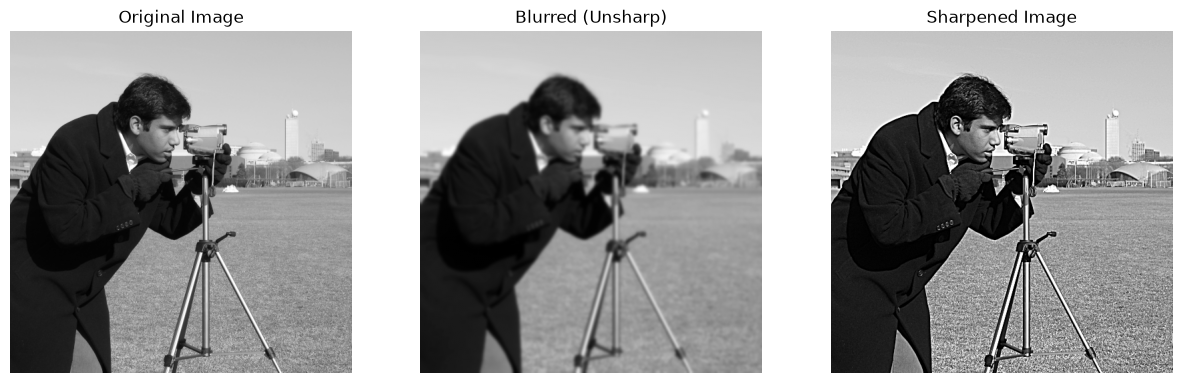

In [3]:
def unsharp_masking(image, sigma=1.0, amount=1.5):
    img_float = image.astype(np.float32)
    blurred = cv2.GaussianBlur(img_float, (0, 0), sigmaX=sigma, sigmaY=sigma)
    mask = img_float - blurred
    sharpened = img_float + amount * mask
    sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)
    return blurred.astype(np.uint8), mask, sharpened

image = data.camera()
blurred, mask, sharpened = unsharp_masking(image, sigma=2.0, amount=1.5)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap='gray')
plt.title('Blurred (Unsharp)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sharpened, cmap='gray')
plt.title('Sharpened Image')
plt.axis('off')

plt.show()

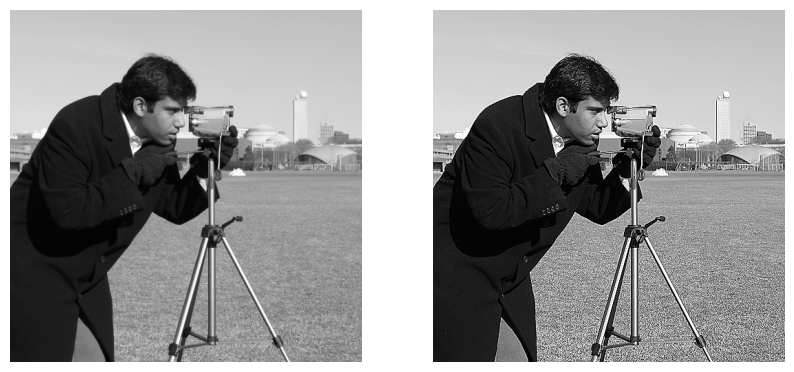

In [4]:
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]], dtype=np.float32)

sharpened_kernel = cv2.filter2D(image, -1, kernel_sharpen)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sharpened_kernel, cmap='gray')
plt.axis('off')

plt.show()

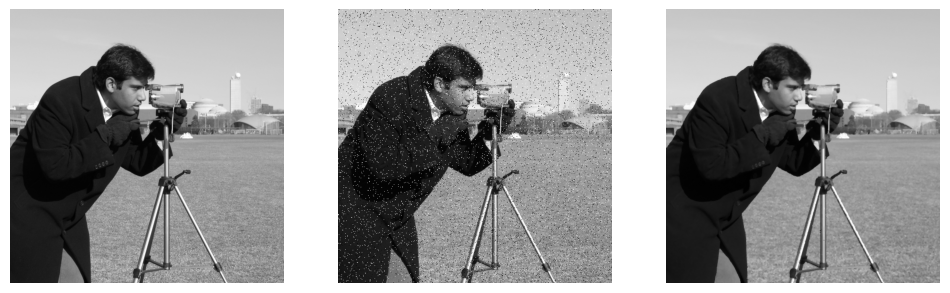

In [5]:
noisy_image = image.copy()
prob = 0.05
rnd = np.random.rand(*image.shape)
noisy_image[rnd < prob/2] = 0
noisy_image[rnd > 1 - prob/2] = 255

median_filtered = cv2.medianBlur(noisy_image, ksize=3)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(noisy_image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(median_filtered, cmap='gray')
plt.axis('off')

plt.show()

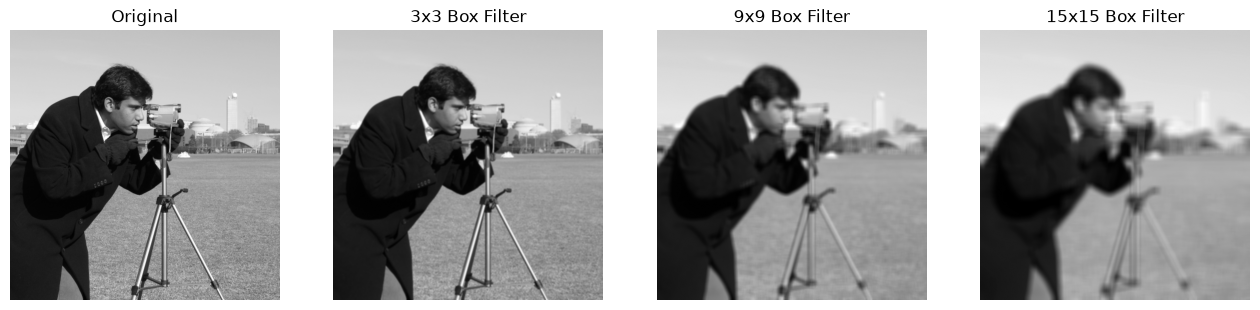

In [6]:
img_box = data.camera()

blur_3x3 = cv2.blur(img_box, (3, 3))
blur_9x9 = cv2.blur(img_box, (9, 9))
blur_15x15 = cv2.blur(img_box, (15, 15))

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_box, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(blur_3x3, cmap='gray')
plt.title('3x3 Box Filter')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(blur_9x9, cmap='gray')
plt.title('9x9 Box Filter')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(blur_15x15, cmap='gray')
plt.title('15x15 Box Filter')
plt.axis('off')

plt.show()

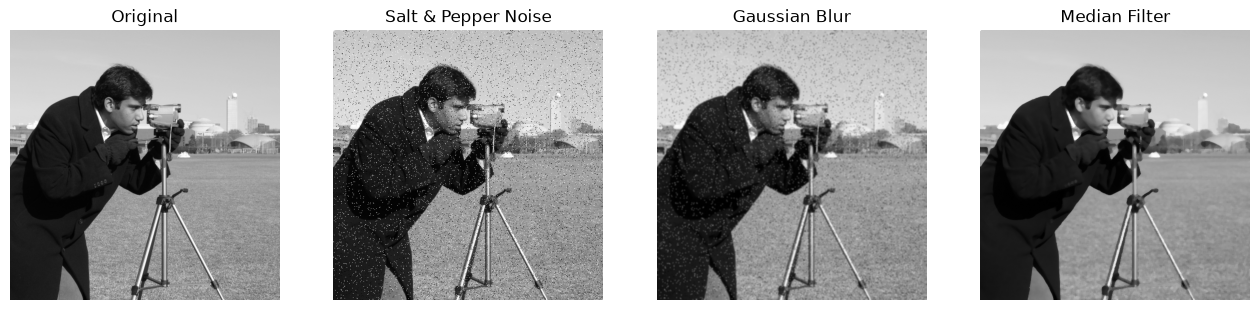

In [7]:
img_sp = data.camera()

noisy_sp = img_sp.copy()
prob = 0.05
rnd = np.random.rand(*img_sp.shape)
noisy_sp[rnd < prob / 2] = 0
noisy_sp[rnd > 1 - prob / 2] = 255

gaussian_sp = cv2.GaussianBlur(noisy_sp, (5, 5), 0)
median_sp = cv2.medianBlur(noisy_sp, 5)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_sp, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(noisy_sp, cmap='gray')
plt.title('Salt & Pepper Noise')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(gaussian_sp, cmap='gray')
plt.title('Gaussian Blur')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(median_sp, cmap='gray')
plt.title('Median Filter')
plt.axis('off')

plt.show()

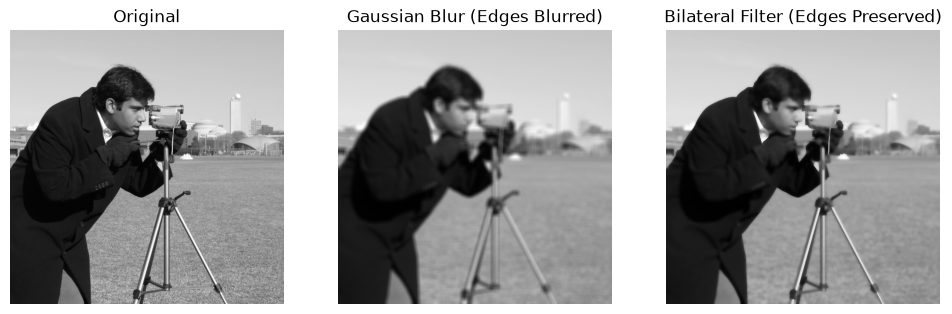

In [8]:
img_bilateral = data.camera()

gaussian_result = cv2.GaussianBlur(img_bilateral, (9, 9), 75)
bilateral_result = cv2.bilateralFilter(img_bilateral, d=9, sigmaColor=75, sigmaSpace=75)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_bilateral, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gaussian_result, cmap='gray')
plt.title('Gaussian Blur (Edges Blurred)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(bilateral_result, cmap='gray')
plt.title('Bilateral Filter (Edges Preserved)')
plt.axis('off')

plt.show()